# Topological charge: reference, two-flow upsampling and HMC on L24

Wilson pure-gauge SU(3), $24^4$, $\beta=6.20$. Every branch uses the same
**Wilson gradient flow, double-precision RK3, $\epsilon=0.02$, $0\le t/a^2\le5$,
measurements every 0.1**, and **unrounded QUDA traceless-clover topological charge**.

The reference plots retain the 30-configuration subset (IDs 0, 10, …, 290)
and all 300 reference fields (IDs 0–299), along with the existing HMC
continuation and fixed-flow-time histories.

The current upsampling comparison uses **all 60 held-out test sources**
(IDs 4, 9, …, 299) and the **v4_8ops_6train** smoother fitted against the
lattice-spacing-matched **βcoarse = 5.775** reference. It compares original
reference fields, the exact full-L24 smeared reference inputs, and the
outputs of **Flow 1 and Flow 2**. This replaces the previous smoother's plots.
All four branches are paired by source ID and start their gradient flow at
zero separately; the learned maps are not assigned gradient-flow time offsets.

The reference FP32 NERSC links are reunitarized on input. Generated and
smeared-reference outputs are exported in FP64 after double-precision SU(3)
reunitarization; its field change is recorded. Neither learned flow output
receives heatbath/HMC rethermalization. The separate HMC experiment runs
300 trajectories from reference ID 299 and measures 30 saved chain states.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable
from IPython.display import Markdown, display

ROOT = next(path for path in (Path.cwd(), Path.cwd().parent) if (path / 'pyproject.toml').exists())
INPUT = ROOT / 'artifacts/4dsu3/L24_beta6p20'
RESULTS = ROOT / 'presentation/results/topo_charge'
FULL_RESULTS = RESULTS / 'full'
HMC_RESULTS = RESULTS / 'hmc'
HMC_FLOW_RESULTS = HMC_RESULTS / 'flow'
HMC_CONFIG_DIR = ROOT / 'temp/topo_charge_hmc_L24'
SMEARING_RUN = ROOT / 'artifacts/4dsu3/downsample/L24_beta6p20_to_L12_beta5p775_polynomial_local_ls_v4_8ops_6train'

# Measurement settings; choose a new RESULTS directory if changing them.
START = 0
STRIDE = 10
N_CONFIGS = 30
EPSILON = 0.02
T_MAX = 5.0
MEASURE_EVERY = 5
HMC_TRAJECTORIES = 300
HMC_SAVE_EVERY = 10
HMC_MD_STEPS = 50
HMC_TRAJECTORY_LENGTH = 1.0
HMC_SEED = 20261015
Q_TRACE_FLOW_TIME = 5.0  # Fixed Wilson-flow time t/a^2 for both iteration histories.

sys.path.insert(0, str(ROOT / 'scripts/heatbath'))
from plot_settings import apply_plot_style
apply_plot_style()
plt.rcParams.update({'figure.dpi': 125, 'axes.labelsize': 16, 'axes.titlesize': 16,
                     'xtick.labelsize': 12, 'ytick.labelsize': 12})

UPSAMPLING_RUN = ROOT / 'artifacts/4dsu3/upsample/L12_to_L24_2flow_v6_8ops_6train'
UPSAMPLING_RESULTS = RESULTS / 'upsampling'


## Load or measure reference L24

The completed result bundle loads without rerunning the GPU measurement. If the output is missing or incomplete, the next cell measures the selected reference configurations through the repository's `.venv`, resuming after the last completed configuration.

All branches explicitly measure $Q$ **after** each requested flow interval, including $t=0$ and the final time.

In [2]:
data_path = RESULTS / 'measurements.npz'
metadata_path = RESULTS / 'run.json'
complete = metadata_path.exists() and json.loads(metadata_path.read_text())['complete']
if not data_path.exists() or not complete:
    command = [str(ROOT / '.venv/bin/python'), str(ROOT / 'scripts/heatbath/topo_charge.py'),
               '--input', str(INPUT), '--output', str(RESULTS),
               '--start', str(START), '--stride', str(STRIDE), '--samples', str(N_CONFIGS),
               '--epsilon', str(EPSILON), '--t-max', str(T_MAX),
               '--measure-every', str(MEASURE_EVERY)]
    subprocess.run(command, cwd=ROOT, check=True)

run = json.loads(metadata_path.read_text())
settings = run['settings']
requested = {'input': str(INPUT.resolve()), 'start': START, 'stride': STRIDE,
             'samples': N_CONFIGS, 'epsilon': EPSILON, 't_max': T_MAX,
             'measure_every': MEASURE_EVERY}
if any(settings[key] != value for key, value in requested.items()):
    raise ValueError('Cached measurements have different settings; choose a new RESULTS directory.')
with np.load(data_path) as saved:
    config_indices = saved['config_indices']
    flow_times = saved['flow_times']
    charge = saved['topological_charge']
    energy = saved['energy']

assert run['complete'] and np.isfinite(charge).all()
print(f"Lattice: {settings['lattice_size']}, beta={settings['beta']}")
print(f'{len(config_indices)} configurations × {len(flow_times)} flow times')
print('Configuration IDs:', config_indices.tolist())
print(f"Integrator: {settings['integrator']}; step {settings['epsilon']}; {settings['precision']} precision")
print(f"t/a²: {flow_times[0]:g}–{flow_times[-1]:g}; measurement interval {EPSILON * MEASURE_EVERY:g}")


Lattice: [24, 24, 24, 24], beta=6.2
30 configurations × 51 flow times
Configuration IDs: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260, 270, 280, 290]
Integrator: QUDA third-order Runge-Kutta (RK3); step 0.02; double precision
t/a²: 0–5; measurement interval 0.1


In [3]:
y_limits = (np.floor(charge.min())-.25, np.ceil(charge.max())+.25)

def plot_charge_curves(values, indices, times, limits, title, filename, output=RESULTS, colorbar_label='Configuration ID'):
    cmap = plt.get_cmap('turbo', len(indices))
    half_spacing = (indices[1] - indices[0]) / 2
    bounds = np.r_[indices - half_spacing, indices[-1] + half_spacing]
    norm = BoundaryNorm(bounds, cmap.N)
    colors = cmap(norm(indices))
    linewidth, alpha = (1.3, 0.85) if len(indices) == 30 else (0.65, 0.6)
    figure, axis = plt.subplots(figsize=(10, 6), constrained_layout=True)
    for index, curve, color in zip(indices, values, colors):
        axis.plot(times, curve, color=color, linewidth=linewidth, alpha=alpha,
                  label=f'cfg {index:04d}')
    guide_step = 1 if limits[1]-limits[0] <= 20 else 10
    for integer in range(int(np.ceil(limits[0]/guide_step))*guide_step, int(np.floor(limits[1])) + 1, guide_step):
        axis.axhline(integer, color='0.7', linestyle=':', linewidth=0.6, zorder=0)
    axis.set(xlabel=r'Gradient-flow time $t/a^2$', ylabel=r'Topological charge $Q(t)$',
             title=title, xlim=(times[0], times[-1]), ylim=limits)
    axis.tick_params(direction='in', top=True, right=True)
    tick_stride = max(1, len(indices) // 10)
    colorbar = figure.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axis,
                              ticks=np.unique(np.r_[indices[::tick_stride], indices[-1]]),
                              fraction=0.035, pad=0.025)
    colorbar.set_label(colorbar_label, fontsize=12)
    figure.savefig(output / f'{filename}.png', dpi=180, bbox_inches='tight')
    figure.savefig(output / f'{filename}.pdf', bbox_inches='tight')
    plt.show()


## Reference L24: 30 charge-evolution curves

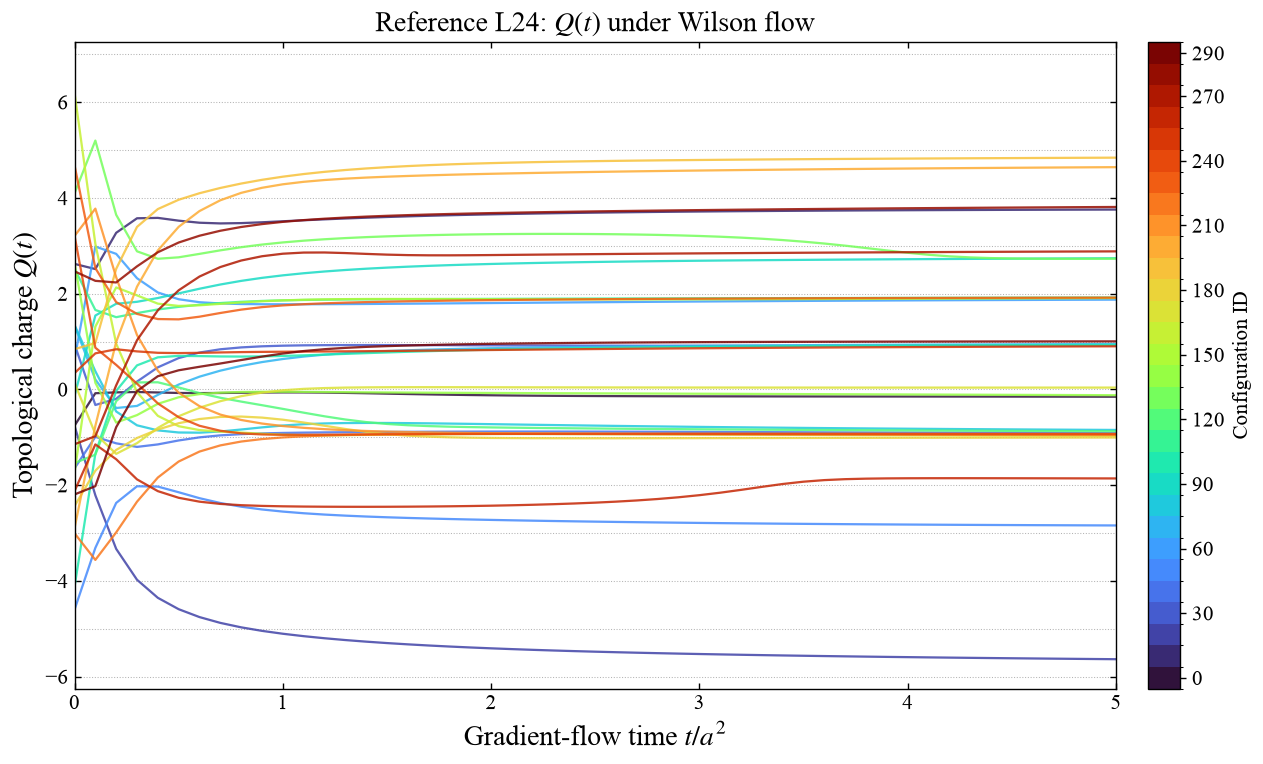

In [4]:
plot_charge_curves(charge, config_indices, flow_times, y_limits,
                   r'Reference L24: $Q(t)$ under Wilson flow', 'topo_charge_flow')

## Complete reference ensemble: all 300 configurations

Reuse the same 30 reference measurements and measure any remaining fields
with identical flow settings. The total plot contains all 300 charge curves;
the two-flow comparison below selects its 60 held-out source IDs from this array.


In [5]:
full_metadata_path = FULL_RESULTS/'run.json'
full_complete = full_metadata_path.exists() and json.loads(full_metadata_path.read_text())['complete']
if not full_complete:
    subprocess.run([str(ROOT/'.venv/bin/python'), str(ROOT/'scripts/heatbath/topo_charge.py'),
                    '--input', str(INPUT), '--output', str(FULL_RESULTS),
                    '--stride', '1', '--samples', '300', '--epsilon', str(EPSILON),
                    '--t-max', str(T_MAX), '--measure-every', str(MEASURE_EVERY),
                    '--reuse-from', str(RESULTS)], cwd=ROOT, check=True)
full_run = json.loads(full_metadata_path.read_text())
expected = dict(requested, start=0, stride=1, samples=300)
assert all(full_run['settings'][key] == value for key, value in expected.items())
with np.load(FULL_RESULTS/'measurements.npz') as saved:
    full_indices = saved['config_indices']
    np.testing.assert_array_equal(full_indices, np.arange(300))
    np.testing.assert_array_equal(saved['flow_times'], flow_times)
    full_charge = saved['topological_charge']
np.testing.assert_array_equal(full_charge[config_indices], charge)
assert full_run['complete'] and full_charge.shape == (300, len(flow_times)) and np.isfinite(full_charge).all()
full_y_limits = (np.floor(full_charge.min())-.25, np.ceil(full_charge.max())+.25)
print(f'{len(full_indices)} reference fields × {len(flow_times)} Wilson-flow times')


300 reference fields × 51 Wilson-flow times


## Reference L24: all 300 charge-evolution curves

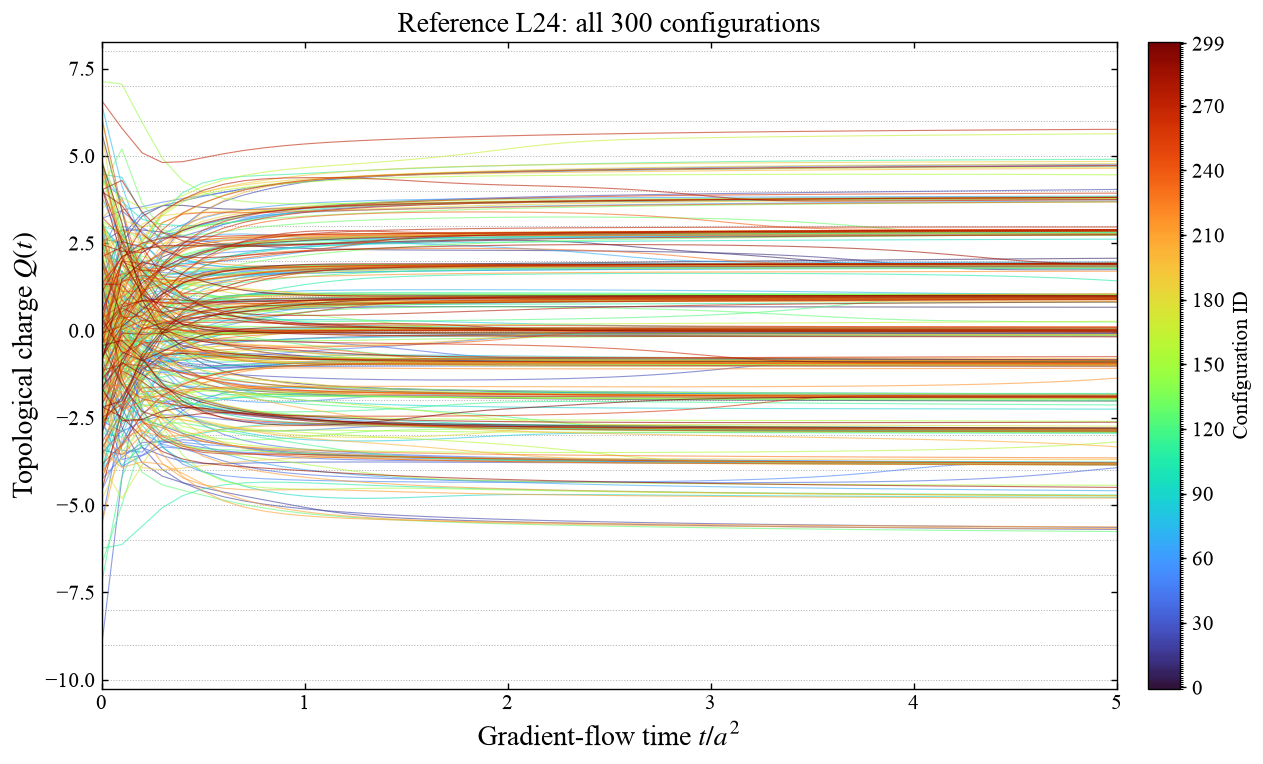

In [6]:
plot_charge_curves(full_charge, full_indices, flow_times, full_y_limits,
                   r'Reference L24: all 300 configurations',
                   'topo_charge_flow_300', output=FULL_RESULTS)

## HMC continuation from the last reference L24 configuration

Start from the **300th heatbath configuration**, `wilson_beta6p20_L24_cfg_0299.nersc` (the files use zero-based indices). The chain uses the same **Wilson pure-gauge SU(3) action, β = 6.20, periodic boundaries and double precision**.

**One HMC step means one complete trajectory including its Metropolis accept/reject test.** Use trajectory length τ = 1, a second-order Omelyan integrator (`O2Nf2Ng0V`, λ = 0.1931833275037836), and **50 MD integration steps per trajectory**, so δτ = 0.02. As in the native PyQUDA HMC example, project the proposal back to SU(3) at the end of each trajectory, with tolerance 2×10⁻¹⁵, **before computing the final Hamiltonian and making the Metropolis decision**. There is no additional warmup: the chain starts from the existing reference field. Rejections retain the previous field and still count toward the requested 300 steps.

Save the actual chain state at **trajectories 10, 20, …, 300** as 30 temporary **FP64 NERSC configurations**, without smearing or blocking. Checkpoints also save the double-precision field and the RNG state, so an interrupted run resumes at the last saved group of 10 trajectories.

Initial-field controls use three momenta at each of 25 and 50 MD steps. With the selected 50 steps and SU(3) projection, proposal acceptance probabilities were 0.81–0.93 and the maximum forward/backward field or momentum error was below 1.1×10⁻¹⁰. The projected two-trajectory checkpoint had unitarity and determinant errors below 1.4×10⁻¹⁵. An interrupted run reproduced the continuous fields, plaquettes, ΔH, acceptance decisions and RNG state exactly. These scoped controls are in `hmc/validation.json`; production acceptance is reported below.


In [7]:
hmc_metadata_path = HMC_RESULTS / 'run.json'
hmc_complete = (hmc_metadata_path.exists()
                and json.loads(hmc_metadata_path.read_text())['complete'])
if not hmc_complete:
    command = [str(ROOT / '.venv/bin/python'), str(ROOT / 'scripts/heatbath/hmc_continue.py'),
               '--input', str(INPUT), '--output', str(HMC_RESULTS),
               '--config-dir', str(HMC_CONFIG_DIR), '--trajectories', str(HMC_TRAJECTORIES),
               '--save-every', str(HMC_SAVE_EVERY), '--md-steps', str(HMC_MD_STEPS),
               '--trajectory-length', str(HMC_TRAJECTORY_LENGTH), '--seed', str(HMC_SEED)]
    subprocess.run(command, cwd=ROOT, check=True)
hmc_run = json.loads(hmc_metadata_path.read_text())
hmc_settings = hmc_run['settings']
hmc_expected = {'trajectories': HMC_TRAJECTORIES, 'save_every': HMC_SAVE_EVERY,
                'md_steps': HMC_MD_STEPS, 'trajectory_length': HMC_TRAJECTORY_LENGTH,
                'seed': HMC_SEED, 'config_dir': str(HMC_CONFIG_DIR.resolve()),
                'projection_tolerance': 2e-15}
assert all(hmc_settings[key] == value for key, value in hmc_expected.items())
reference_manifest = json.loads((INPUT / 'ensemble.json').read_text())
last_reference = max(reference_manifest['configurations'], key=lambda record: record['index'])
assert hmc_settings['source'] == {'input': str(INPUT.resolve()), **last_reference}
with np.load(HMC_RESULTS / 'chain.npz') as saved:
    hmc_trajectories = saved['trajectories']
    hmc_plaquette = saved['plaquette']
    hmc_delta_h = saved['delta_h']
    hmc_accepted = saved['accepted']
np.testing.assert_array_equal(hmc_trajectories, np.arange(HMC_TRAJECTORIES + 1))
assert hmc_run['complete'] and np.isfinite(hmc_plaquette).all() and np.isfinite(hmc_delta_h).all()
print('Starting reference file:', hmc_settings['source']['filename'])
print(f"Completed: {hmc_run['completed_trajectories']} trajectories; saved {hmc_run['saved_configurations']} fields")
print(f"Metropolis acceptance: {hmc_accepted.sum()}/{len(hmc_accepted)} = {hmc_accepted.mean():.1%}")
print(f'Initial plaquette: {hmc_plaquette[0]:.10f}; final plaquette: {hmc_plaquette[-1]:.10f}')

Starting reference file: wilson_beta6p20_L24_cfg_0299.nersc
Completed: 300 trajectories; saved 30 fields
Metropolis acceptance: 265/300 = 88.3%
Initial plaquette: 0.6136007864; final plaquette: 0.6135260004


## Plaquette evolution over 300 HMC trajectories

Measure the mean plaquette **after the Metropolis decision at every trajectory**. Step 0 is the original last reference field.

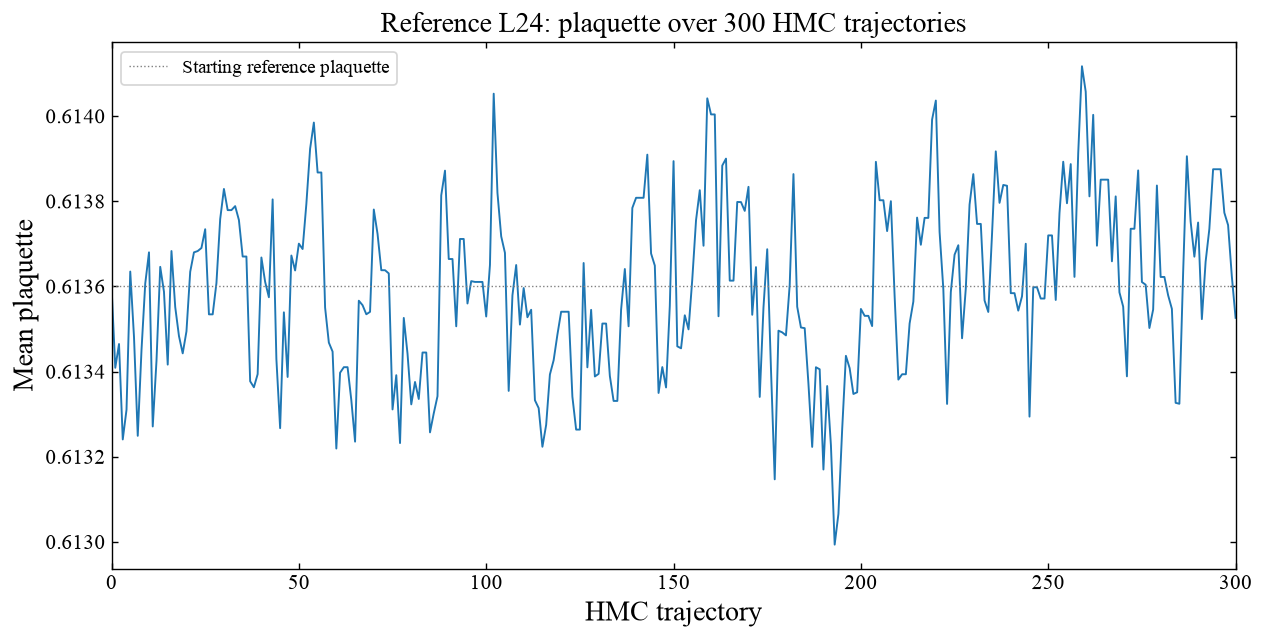

In [8]:
figure, axis = plt.subplots(figsize=(10, 5), constrained_layout=True)
axis.plot(hmc_trajectories, hmc_plaquette, color='C0', linewidth=1.1)
axis.axhline(hmc_plaquette[0], color='0.5', linestyle=':', linewidth=0.8,
             label='Starting reference plaquette')
axis.set(xlabel='HMC trajectory', ylabel='Mean plaquette',
         title='Reference L24: plaquette over 300 HMC trajectories',
         xlim=(0, HMC_TRAJECTORIES))
axis.tick_params(direction='in', top=True, right=True)
axis.ticklabel_format(axis='y', style='plain', useOffset=False)
axis.legend(fontsize=11)
figure.savefig(HMC_RESULTS / 'plaquette_hmc_300.png', dpi=180, bbox_inches='tight')
figure.savefig(HMC_RESULTS / 'plaquette_hmc_300.pdf', bbox_inches='tight')
plt.show()

## Gradient-flow topological charge of the 30 HMC snapshots

Apply the **same Wilson gradient flow and unrounded clover Q measurement** to each saved HMC state: t/a² = 0–5, double-precision RK3 with ε = 0.02, measured every 0.1. Flowed fields are separate measurements; they are not fed back into the HMC chain.

The following figure contains **all 30 charge-evolution curves in one plot**. Colors identify the HMC trajectory at which each field was saved.

In [9]:
hmc_flow_metadata_path = HMC_FLOW_RESULTS / 'run.json'
hmc_flow_complete = (hmc_flow_metadata_path.exists()
                     and json.loads(hmc_flow_metadata_path.read_text())['complete'])
if not hmc_flow_complete:
    command = [str(ROOT / '.venv/bin/python'), str(ROOT / 'scripts/heatbath/topo_charge.py'),
               '--input', str(HMC_CONFIG_DIR), '--output', str(HMC_FLOW_RESULTS),
               '--stride', '1', '--samples', str(HMC_TRAJECTORIES // HMC_SAVE_EVERY),
               '--epsilon', str(EPSILON), '--t-max', str(T_MAX),
               '--measure-every', str(MEASURE_EVERY)]
    subprocess.run(command, cwd=ROOT, check=True)
hmc_flow_run = json.loads(hmc_flow_metadata_path.read_text())
assert hmc_flow_run['settings']['hmc_settings'] == hmc_settings
assert hmc_flow_run['settings']['epsilon'] == EPSILON
assert hmc_flow_run['settings']['t_max'] == T_MAX
assert hmc_flow_run['settings']['measure_every'] == MEASURE_EVERY
with np.load(HMC_FLOW_RESULTS / 'measurements.npz') as saved:
    hmc_snapshot_indices = saved['config_indices']
    hmc_flow_times = saved['flow_times']
    hmc_charge = saved['topological_charge']
    hmc_initial_plaquette = saved['initial_plaquette']
np.testing.assert_array_equal(hmc_snapshot_indices,
                              np.arange(HMC_SAVE_EVERY, HMC_TRAJECTORIES + 1, HMC_SAVE_EVERY))
np.testing.assert_array_equal(hmc_flow_times, flow_times)
np.testing.assert_allclose(hmc_initial_plaquette, hmc_plaquette[hmc_snapshot_indices], rtol=0, atol=1e-12)
assert hmc_flow_run['complete'] and hmc_charge.shape == (30, len(flow_times)) and np.isfinite(hmc_charge).all()
hmc_y_limits = (np.floor(hmc_charge.min()) - 0.25, np.ceil(hmc_charge.max()) + 0.25)
print(f'{len(hmc_snapshot_indices)} HMC snapshots × {len(hmc_flow_times)} flow times')

30 HMC snapshots × 51 flow times


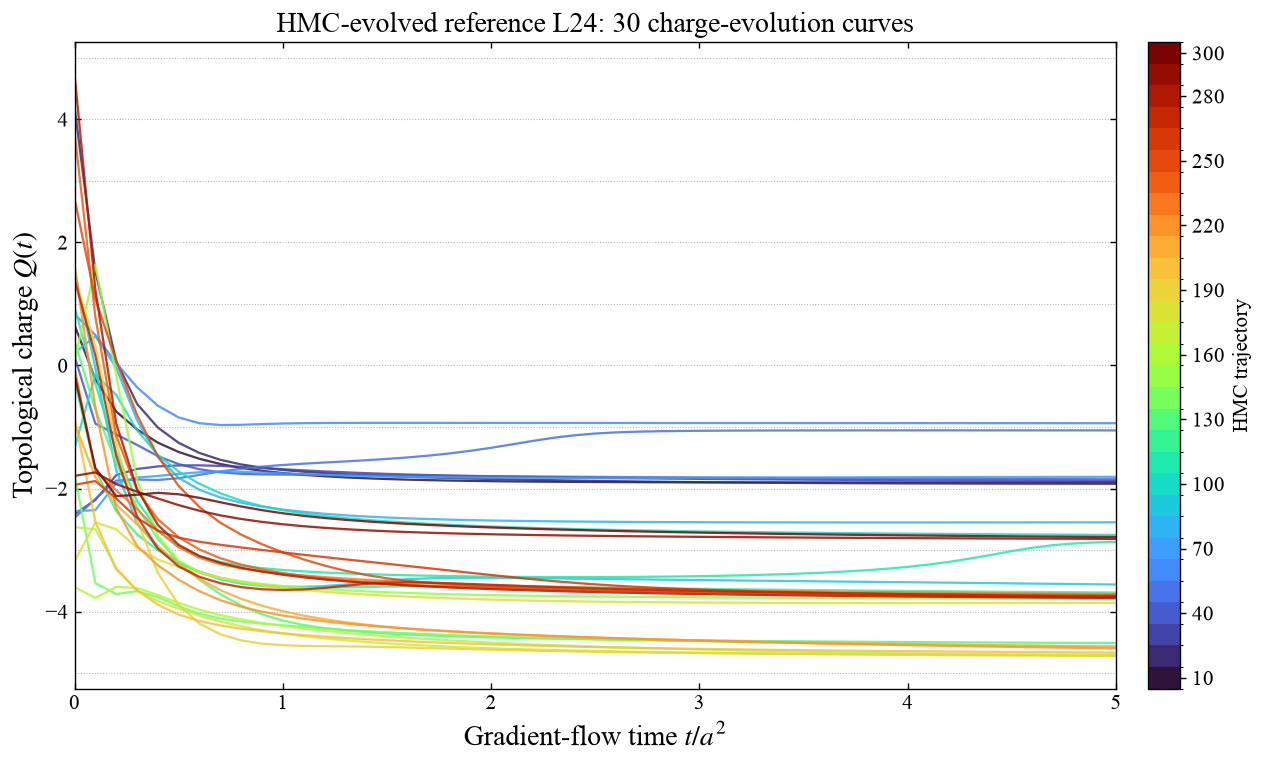

In [10]:
plot_charge_curves(hmc_charge, hmc_snapshot_indices, hmc_flow_times, hmc_y_limits,
                   r'HMC-evolved reference L24: 30 charge-evolution curves',
                   'topo_charge_hmc_flow', output=HMC_RESULTS,
                   colorbar_label='HMC trajectory')

## Topological charge versus iteration at fixed flow time

Use the **unrounded clover charge at $t/a^2=5$** for both histories. Change `Q_TRACE_FLOW_TIME` to `3.0` to use the other measured time without rerunning gradient flow.

- **Unsmeared reference L24:** all 300 configuration IDs 0–299. Within each HB stream, adjacent saved configurations are separated by **100 HB update steps**. Each update step consists of **1 heatbath sweep + 4 overrelaxation sweeps**, followed by reunitarization. The first 50 configurations (seed 1234) and the remaining 250 (seed 1235) are **independent hot-start streams**; the line is broken between IDs 49 and 50.
- **HMC:** the 30 measured snapshots are separated by **10 complete HMC trajectories**, including accept/reject decisions. Each trajectory has MD length 1 and 50 Omelyan integration steps. The star at trajectory 0 uses the last reference configuration's charge at the same flow time, marking the common starting field.

The two figures share their vertical limits. The horizontal axes retain each algorithm's recorded iteration convention and sampling interval.

In [11]:
history_column = np.flatnonzero(np.isclose(flow_times, Q_TRACE_FLOW_TIME, rtol=0, atol=1e-12)).item()
reference_records = sorted(reference_manifest['configurations'], key=lambda record: record['index'])
np.testing.assert_array_equal(full_indices, [record['index'] for record in reference_records])
hb_steps = np.asarray([record['step'] for record in reference_records])
hb_seeds = np.asarray([record.get('seed', reference_manifest['seed']) for record in reference_records])
hb_chain_breaks = np.flatnonzero(np.diff(hb_seeds) != 0) + 1
hb_separation = reference_manifest['separation_steps']
np.testing.assert_array_equal(np.diff(hb_steps)[np.diff(hb_seeds) == 0], hb_separation)
np.testing.assert_array_equal(np.diff(hmc_snapshot_indices), hmc_settings['save_every'])
reference_history_charge = full_charge[:, history_column]
source_row = np.flatnonzero(full_indices == hmc_settings['source']['index']).item()
hmc_history_trajectories = np.r_[0, hmc_snapshot_indices]
hmc_history_charge = np.r_[reference_history_charge[source_row], hmc_charge[:, history_column]]
history_y_limits = (np.floor(min(reference_history_charge.min(), hmc_history_charge.min())) - 0.25,
                    np.ceil(max(reference_history_charge.max(), hmc_history_charge.max())) + 0.25)

np.savez_compressed(RESULTS / 'charge_history.npz', flow_time=Q_TRACE_FLOW_TIME,
                    reference_config_indices=full_indices, reference_charge=reference_history_charge,
                    reference_generation_steps=hb_steps, reference_seeds=hb_seeds,
                    hmc_trajectories=hmc_history_trajectories, hmc_charge=hmc_history_charge)
history_metadata = {
    'flow_time_t_over_a_squared': Q_TRACE_FLOW_TIME,
    'charge_operator': 'unrounded clover Q, same Wilson flow as the charge-evolution figures',
    'reference': {'measurements': 'full/measurements.npz', 'configurations': len(full_indices),
                  'steps_between_points_within_stream': hb_separation,
                  'heatbath_sweeps_per_step': reference_manifest['heatbath_hits_per_step'],
                  'overrelaxation_sweeps_per_step': reference_manifest['overrelaxation_hits_per_step'],
                  'independent_hot_start_config_ids': full_indices[hb_chain_breaks].tolist()},
    'hmc': {'measurements': 'hmc/flow/measurements.npz', 'measured_snapshots': len(hmc_snapshot_indices),
            'trajectories_between_points': hmc_settings['save_every'],
            'md_steps_per_trajectory': hmc_settings['md_steps'],
            'trajectory_length': hmc_settings['trajectory_length'],
            'trajectory_zero': f"reference configuration ID {hmc_settings['source']['index']} at the same flow time"},
}
(RESULTS / 'charge_history.json').write_text(json.dumps(history_metadata, indent=2) + '\n')
print(f'Fixed flow time: t/a² = {flow_times[history_column]:g}; charges are unrounded')
print(f'HB: {len(full_indices)} configurations, {hb_separation} compound updates between points within each stream')
print('Independent HB hot starts at IDs:', full_indices[hb_chain_breaks].tolist())
print(f"HMC: {len(hmc_snapshot_indices)} measured snapshots, {hmc_settings['save_every']} trajectories between points; trajectory 0 is the reference starting field")

Fixed flow time: t/a² = 5; charges are unrounded
HB: 300 configurations, 100 compound updates between points within each stream
Independent HB hot starts at IDs: [50]
HMC: 30 measured snapshots, 10 trajectories between points; trajectory 0 is the reference starting field


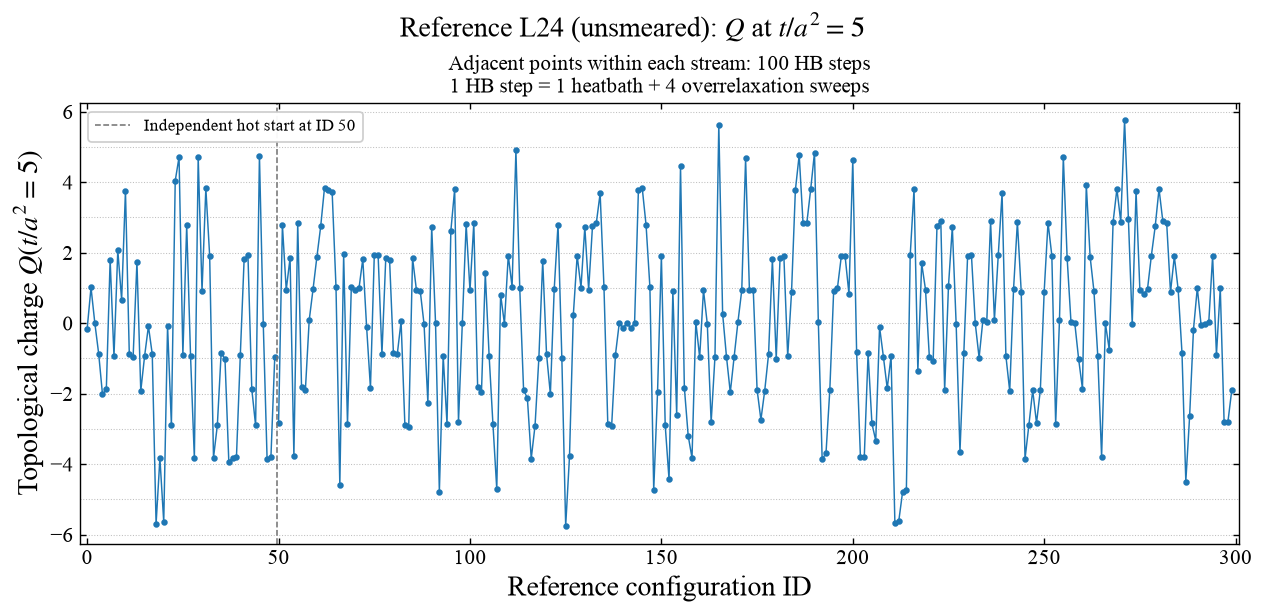

In [12]:
figure, axis = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
for rows in np.split(np.arange(len(full_indices)), hb_chain_breaks):
    axis.plot(full_indices[rows], reference_history_charge[rows], '-o', color='C0',
              linewidth=0.85, markersize=2.7)
for row in hb_chain_breaks:
    boundary = (full_indices[row - 1] + full_indices[row]) / 2
    axis.axvline(boundary, color='0.45', linestyle='--', linewidth=0.9,
                 label=f'Independent hot start at ID {full_indices[row]}')
for integer in range(int(np.ceil(history_y_limits[0])), int(np.floor(history_y_limits[1])) + 1):
    axis.axhline(integer, color='0.75', linestyle=':', linewidth=0.6, zorder=0)
figure.suptitle(rf'Reference L24 (unsmeared): $Q$ at $t/a^2={Q_TRACE_FLOW_TIME:g}$', fontsize=16)
axis.set_title(f'Adjacent points within each stream: {hb_separation} HB steps\n'
               f"1 HB step = {reference_manifest['heatbath_hits_per_step']} heatbath + "
               f"{reference_manifest['overrelaxation_hits_per_step']} overrelaxation sweeps", fontsize=12)
axis.set(xlabel='Reference configuration ID', ylabel=rf'Topological charge $Q(t/a^2={Q_TRACE_FLOW_TIME:g})$',
         xlim=(full_indices[0] - 2, full_indices[-1] + 2), ylim=history_y_limits)
axis.tick_params(direction='in', top=True, right=True)
axis.legend(loc='upper left', fontsize=10, framealpha=0.95)
figure.savefig(FULL_RESULTS / 'topo_charge_reference_history.png', dpi=180, bbox_inches='tight')
figure.savefig(FULL_RESULTS / 'topo_charge_reference_history.pdf', bbox_inches='tight')
plt.show()

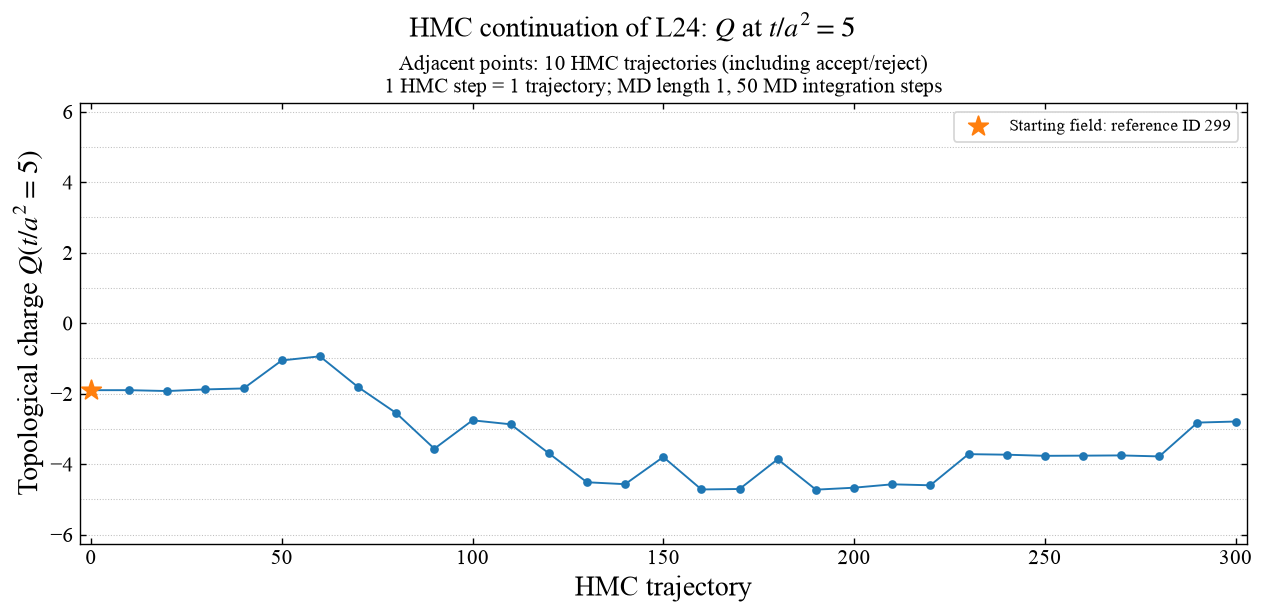

In [13]:
figure, axis = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
axis.plot(hmc_history_trajectories, hmc_history_charge, '-o', color='C0',
          linewidth=1.1, markersize=4)
axis.scatter([0], [hmc_history_charge[0]], marker='*', s=140, color='C1', zorder=3,
             label=f"Starting field: reference ID {hmc_settings['source']['index']}")
for integer in range(int(np.ceil(history_y_limits[0])), int(np.floor(history_y_limits[1])) + 1):
    axis.axhline(integer, color='0.75', linestyle=':', linewidth=0.6, zorder=0)
figure.suptitle(rf'HMC continuation of L24: $Q$ at $t/a^2={Q_TRACE_FLOW_TIME:g}$', fontsize=16)
axis.set_title(f"Adjacent points: {hmc_settings['save_every']} HMC trajectories (including accept/reject)\n"
               f"1 HMC step = 1 trajectory; MD length {hmc_settings['trajectory_length']:g}, "
               f"{hmc_settings['md_steps']} MD integration steps", fontsize=12)
axis.set(xlabel='HMC trajectory', ylabel=rf'Topological charge $Q(t/a^2={Q_TRACE_FLOW_TIME:g})$',
         xlim=(-3, HMC_TRAJECTORIES + 3), ylim=history_y_limits)
axis.tick_params(direction='in', top=True, right=True)
axis.legend(loc='upper right', fontsize=10)
figure.savefig(HMC_RESULTS / 'topo_charge_hmc_history.png', dpi=180, bbox_inches='tight')
figure.savefig(HMC_RESULTS / 'topo_charge_hmc_history.pdf', bbox_inches='tight')
plt.show()

## Two-flow outputs: the same 60 held-out sources

The fresh two-flow experiment uses the current **v4_8ops_6train** smoother,
fitted against the lattice-spacing-matched **βcoarse = 5.775** reference.
For each held-out fine source $U$, form $C=B(S(U))$, sample one conditional
Flow-1 output $\widetilde S=F_1(C,z)$ and then apply
$\widetilde U=F_2(\widetilde S)$. The latent seed is **1234 + 30000 + source ID**.
No Monte Carlo updates are applied to either output.

The following two figures use all **60 test sources (IDs 4, 9, …, 299)**,
the exact outputs evaluated in `upsampling_2flow.ipynb`, and the same colors
and vertical limits. Wilson gradient flow starts at zero separately for each
stage: **$t/a^2=0$–5, double-precision RK3, ε = 0.02, measurements every 0.1**.
Charges remain unrounded. Flow-1 and Flow-2 fields are saved in FP64 NERSC
after double-precision SU(3) reunitarization, with the maximum change recorded
below. This is preparation for the common Wilson-flow measurement.

The paired smeared reference is measured from the exact cached training-map
output; the raw fine reference reuses the existing 300-field measurement.
Source IDs pair conditional samples, and do not form a continuous Monte Carlo
trajectory through the generated fields.


In [14]:
import hashlib
upsampling_run = json.loads((UPSAMPLING_RUN/'run.json').read_text())
upsampling_hash = hashlib.sha256((UPSAMPLING_RUN/'flows.pt').read_bytes()).hexdigest()
assert upsampling_hash == upsampling_run['checkpoint_sha256']
assert upsampling_run['downsampling_checkpoint_sha256'] == hashlib.sha256((SMEARING_RUN/'kernel.pt').read_bytes()).hexdigest()
upsampling_ids = np.asarray(upsampling_run['test_indices'])
np.testing.assert_array_equal(upsampling_ids, np.arange(4, 300, 5))
reference_hashes = {r['index']: r['sha256'] for r in full_run['settings']['configurations']}
fine_hashes = {r['index']: r['sha256'] for r in upsampling_run['fine_manifest']['configurations']}
assert all(reference_hashes[int(index)] == fine_hashes[int(index)] for index in upsampling_ids)
upsampling_charges = {'reference': full_charge[upsampling_ids]}
projection_changes = {}
for stage in ('flow1', 'flow2', 'smeared_reference'):
    directory = UPSAMPLING_RESULTS/stage
    metadata_path = directory/'run.json'
    complete = metadata_path.exists() and json.loads(metadata_path.read_text())['complete']
    if not complete:
        subprocess.run([str(ROOT/'.venv/bin/python'), str(ROOT/'scripts/heatbath/topo_charge.py'),
                        '--input', str(UPSAMPLING_RUN/'generated_fields'/stage), '--output', str(directory),
                        '--stride', '1', '--samples', str(len(upsampling_ids)), '--epsilon', str(EPSILON),
                        '--t-max', str(T_MAX), '--measure-every', str(MEASURE_EVERY)], cwd=ROOT, check=True)
    stage_run = json.loads(metadata_path.read_text())
    stage_settings = stage_run['settings']
    assert stage_settings['upsampling']['checkpoint_sha256'] == upsampling_hash
    assert stage_settings['upsampling']['downsampling_checkpoint_sha256'] == upsampling_run['downsampling_checkpoint_sha256']
    assert stage_settings['upsampling']['stage'] == stage
    assert stage_settings['epsilon'] == EPSILON and stage_settings['t_max'] == T_MAX
    assert stage_settings['measure_every'] == MEASURE_EVERY and stage_settings['precision'] == 'double'
    with np.load(directory/'measurements.npz') as saved:
        np.testing.assert_array_equal(saved['config_indices'], upsampling_ids)
        np.testing.assert_array_equal(saved['flow_times'], flow_times)
        upsampling_charges[stage] = saved['topological_charge']
    assert upsampling_charges[stage].shape == (60, len(flow_times))
    assert np.isfinite(upsampling_charges[stage]).all()
    manifest = json.loads((UPSAMPLING_RUN/'generated_fields'/stage/'ensemble.json').read_text())
    projection_changes[stage] = max(r['double_reunitarization_max_abs_change'] for r in manifest['configurations'])
upsampling_limits = (np.floor(min(q.min() for q in upsampling_charges.values()))-.25,
                     np.ceil(max(q.max() for q in upsampling_charges.values()))+.25)
np.savez_compressed(UPSAMPLING_RESULTS/'charge_comparison.npz', config_indices=upsampling_ids,
                    flow_times=flow_times, **upsampling_charges)
print('Two-flow checkpoint:', upsampling_hash)
print('Maximum double-reunitarization field changes:', projection_changes)
print('Paired sources:', upsampling_ids.tolist())


Two-flow checkpoint: 92a15eebdb830f1bfae8e7dbd270479f2893c95028c1fa0efbdf5d236421c733
Maximum double-reunitarization field changes: {'flow1': 1.3378638615142661e-06, 'flow2': 1.3062090037832455e-06, 'smeared_reference': 1.1416350794822411e-06}
Paired sources: [4, 9, 14, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 84, 89, 94, 99, 104, 109, 114, 119, 124, 129, 134, 139, 144, 149, 154, 159, 164, 169, 174, 179, 184, 189, 194, 199, 204, 209, 214, 219, 224, 229, 234, 239, 244, 249, 254, 259, 264, 269, 274, 279, 284, 289, 294, 299]


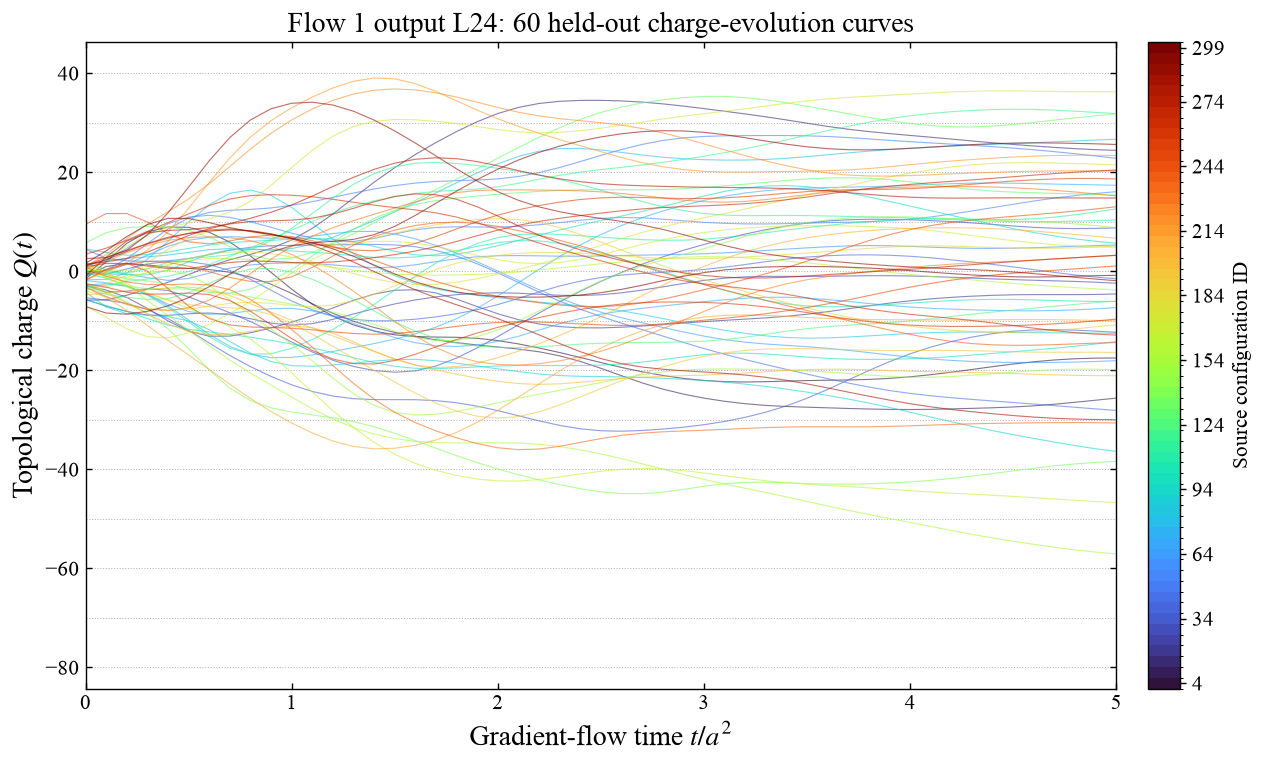

In [15]:
plot_charge_curves(upsampling_charges['flow1'], upsampling_ids, flow_times, upsampling_limits,
                   r'Flow 1 output L24: 60 held-out charge-evolution curves',
                   'topo_charge_flow1', output=UPSAMPLING_RESULTS, colorbar_label='Source configuration ID')


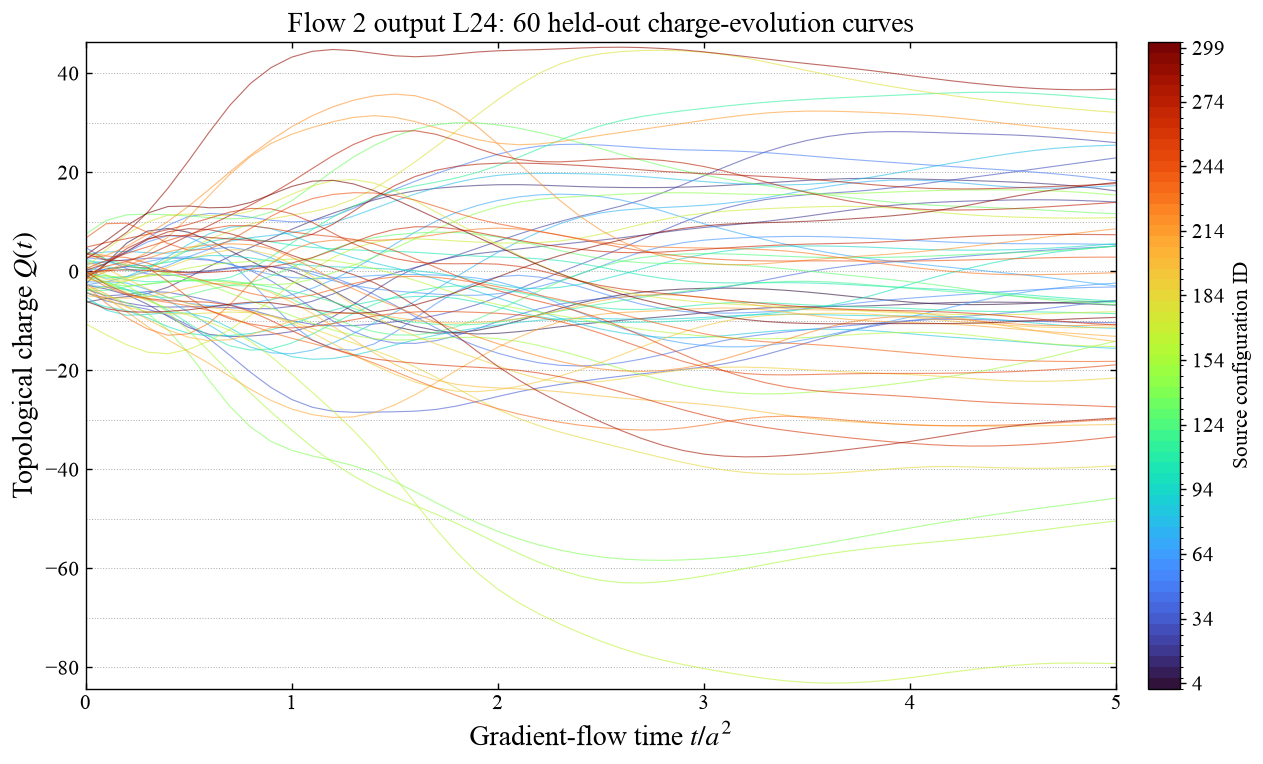

In [16]:
plot_charge_curves(upsampling_charges['flow2'], upsampling_ids, flow_times, upsampling_limits,
                   r'Flow 2 output L24: 60 held-out charge-evolution curves',
                   'topo_charge_flow2', output=UPSAMPLING_RESULTS, colorbar_label='Source configuration ID')


## Compare the reference and both generated stages

These four panels show the **same 60 source IDs**, with identical colors and
axis limits. The fixed-time distribution below uses **unrounded $Q(t/a^2=5)$**.
The paired differences are descriptive; the generative flows are not constrained
to reproduce each source's topological charge, and charge agreement is not
used for training or checkpoint selection.


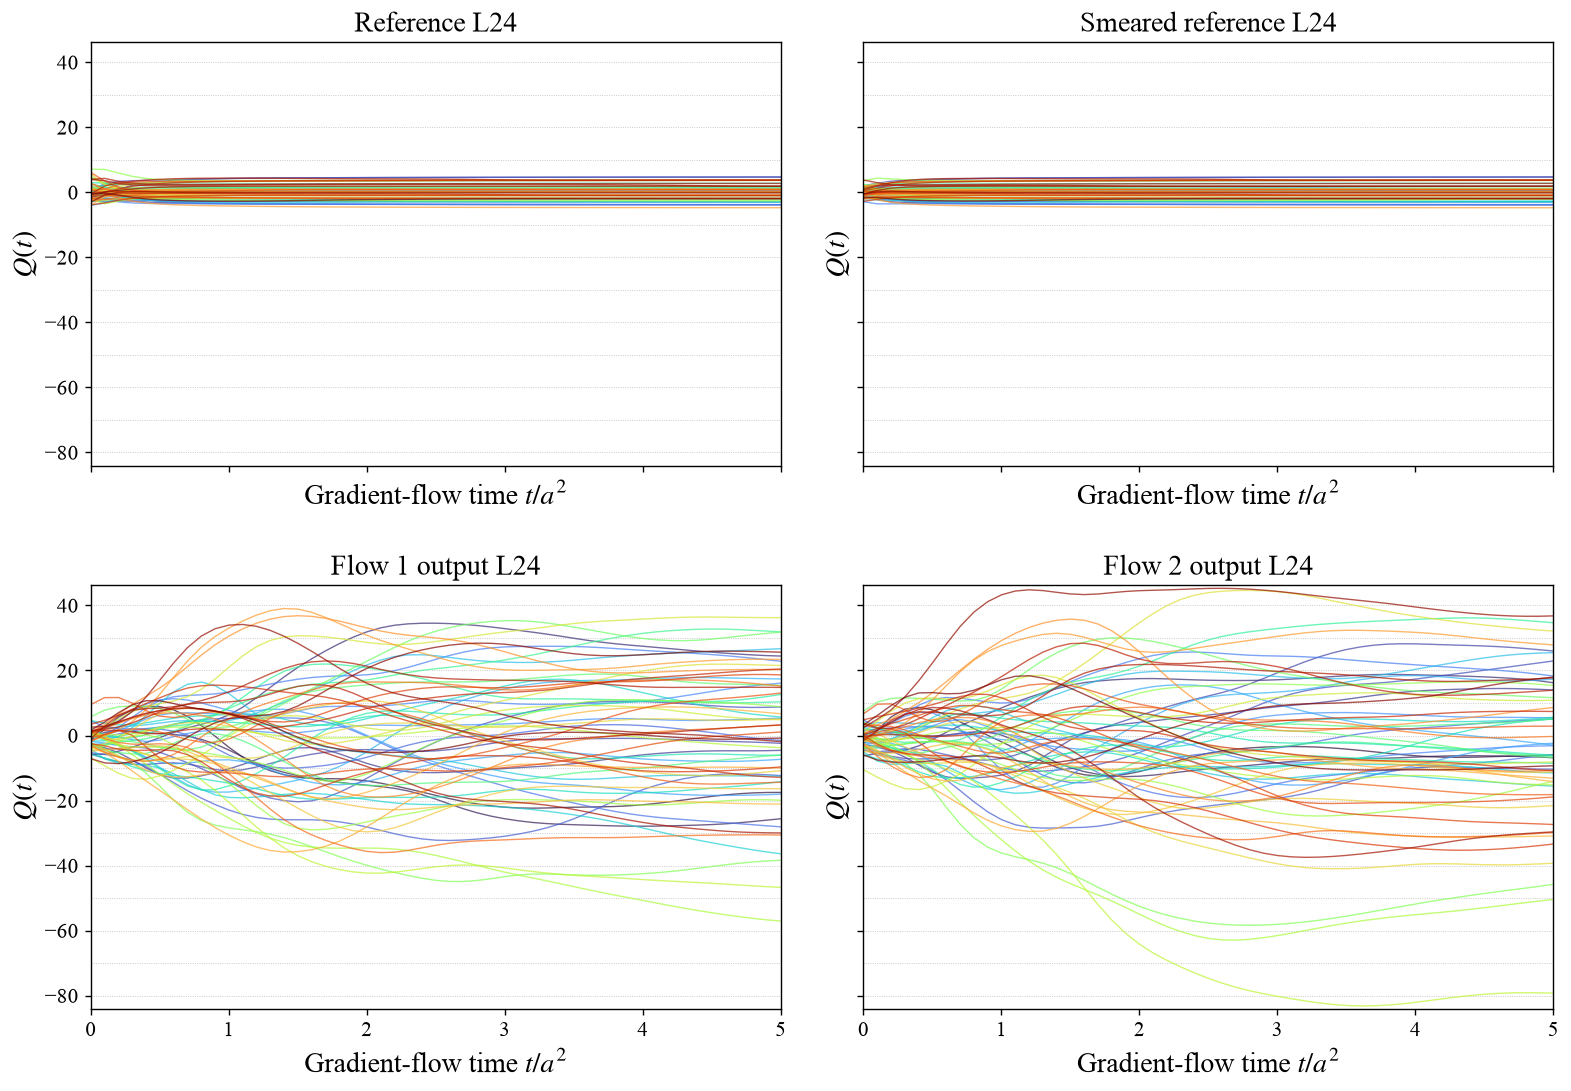

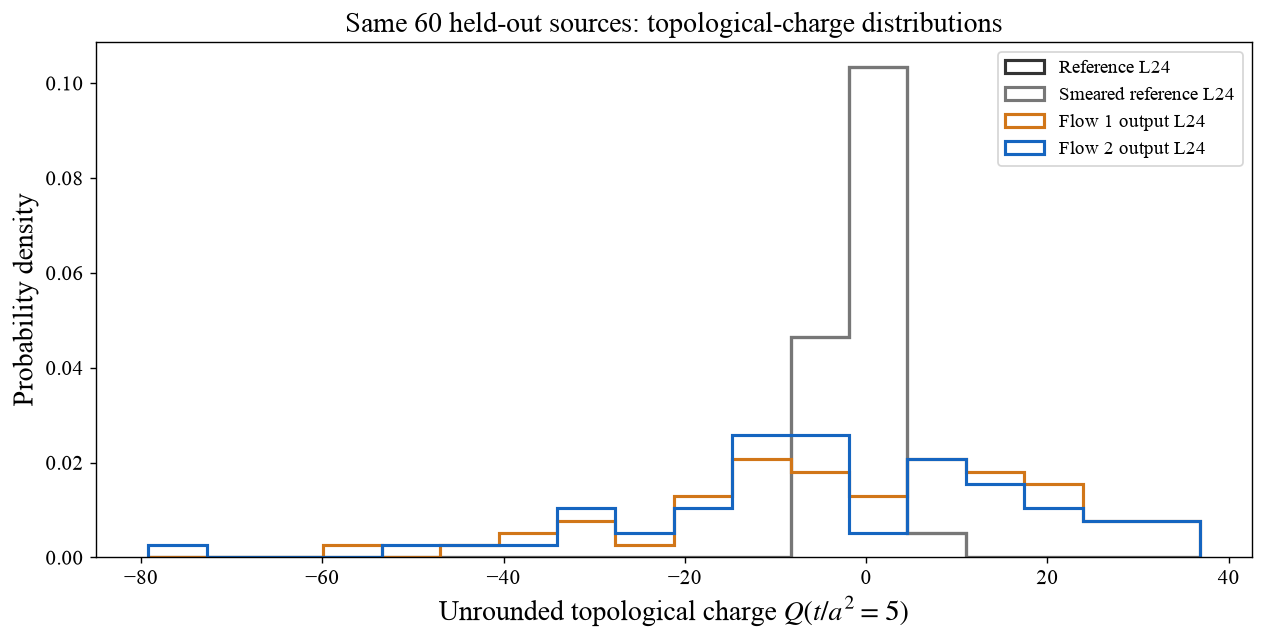

| Stage | Mean Q(0) | Mean Q(5) | SD Q(5) | ⟨Q(5)²⟩ | Mean absolute paired ΔQ(5) |
| --- | ---: | ---: | ---: | ---: | ---: |
| Reference L24 | +0.2292 | +0.0149 | 2.3965 | 5.6477 | 0.0000 |
| Smeared reference L24 | -0.0611 | +0.0306 | 2.3935 | 5.6341 | 0.0374 |
| Flow 1 output L24 | -0.8078 | -0.7517 | 20.4266 | 410.8556 | 16.2614 |
| Flow 2 output L24 | -0.6598 | -3.6556 | 21.9517 | 487.2075 | 16.7124 |

Wilson-flow half-step checks (first held-out source per stage): {'flow1': {'source_index': 4, 'production_epsilon': 0.02, 'check_epsilon': 0.01, 't_max': 5.0, 'maximum_absolute_charge_difference': 0.0012656818062311004, 'final_charge_difference': -0.0012656818062311004, 'maximum_absolute_energy_difference': 2.2586536048141426e-06}, 'flow2': {'source_index': 4, 'production_epsilon': 0.02, 'check_epsilon': 0.01, 't_max': 5.0, 'maximum_absolute_charge_difference': 0.0008654095530147288, 'final_charge_difference': 9.191956791188005e-05, 'maximum_absolute_energy_difference': 2.045820870044679e-06}}


In [17]:
stage_labels = {'reference': 'Reference L24', 'smeared_reference': 'Smeared reference L24',
                'flow1': 'Flow 1 output L24', 'flow2': 'Flow 2 output L24'}
colors = plt.get_cmap('turbo', len(upsampling_ids))(np.arange(len(upsampling_ids)))
figure, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True, constrained_layout=False)
figure.subplots_adjust(left=.08, right=.98, bottom=.09, top=.95, hspace=.28, wspace=.12)
for axis, (stage, label) in zip(axes.flat, stage_labels.items()):
    for curve, color in zip(upsampling_charges[stage], colors):
        axis.plot(flow_times, curve, color=color, linewidth=.8, alpha=.7)
    guide_step = 1 if upsampling_limits[1]-upsampling_limits[0] <= 20 else 10
    for integer in range(int(np.ceil(upsampling_limits[0]/guide_step))*guide_step,
                         int(np.floor(upsampling_limits[1]))+1, guide_step):
        axis.axhline(integer, color='.75', linestyle=':', linewidth=.5, zorder=0)
    axis.set(title=label, xlabel=r'Gradient-flow time $t/a^2$', ylabel=r'$Q(t)$',
             xlim=(0, T_MAX), ylim=upsampling_limits)
figure.savefig(UPSAMPLING_RESULTS/'topo_charge_stage_comparison.png', dpi=180, bbox_inches='tight')
figure.savefig(UPSAMPLING_RESULTS/'topo_charge_stage_comparison.pdf', bbox_inches='tight')
plt.show()

comparison_time = float(flow_times[-1])
column = len(flow_times)-1
figure, axis = plt.subplots(figsize=(10, 5), constrained_layout=True)
bins = np.histogram_bin_edges(np.concatenate([q[:, column] for q in upsampling_charges.values()]), bins=18)
for color, (stage, label) in zip(['#333333', '#777777', '#d17618', '#1565c0'], stage_labels.items()):
    axis.hist(upsampling_charges[stage][:, column], bins=bins, density=True, histtype='step',
              linewidth=1.8, color=color, label=label)
axis.set(xlabel=rf'Unrounded topological charge $Q(t/a^2={comparison_time:g})$',
         ylabel='Probability density', title='Same 60 held-out sources: topological-charge distributions')
axis.legend(fontsize=11)
figure.savefig(UPSAMPLING_RESULTS/'topo_charge_stage_distribution.png', dpi=180, bbox_inches='tight')
figure.savefig(UPSAMPLING_RESULTS/'topo_charge_stage_distribution.pdf', bbox_inches='tight')
plt.show()

summary = {'checkpoint_sha256': upsampling_hash,
           'downsampling_checkpoint_sha256': upsampling_run['downsampling_checkpoint_sha256'],
           'config_indices': upsampling_ids.tolist(), 'flow_time': comparison_time,
           'epsilon': EPSILON, 't_max': T_MAX, 'measure_every': MEASURE_EVERY,
           'charge_operator': 'unrounded QUDA clover Q after Wilson flow',
           'maximum_reunitarization_field_changes': projection_changes, 'stages': {}}
rows = ['| Stage | Mean Q(0) | Mean Q(5) | SD Q(5) | ⟨Q(5)²⟩ | Mean absolute paired ΔQ(5) |',
        '| --- | ---: | ---: | ---: | ---: | ---: |']
for stage, label in stage_labels.items():
    q = upsampling_charges[stage]
    target = upsampling_charges['smeared_reference' if stage == 'flow1' else 'reference'][:, column]
    final = q[:, column]
    record = dict(mean_q0=float(q[:, 0].mean()), mean_q5=float(final.mean()),
                  std_q5=float(final.std(ddof=1)), mean_q5_squared=float(np.mean(final**2)),
                  mean_absolute_paired_difference=float(np.abs(final-target).mean()))
    summary['stages'][stage] = record
    rows.append(f"| {label} | {record['mean_q0']:+.4f} | {record['mean_q5']:+.4f} | {record['std_q5']:.4f} | {record['mean_q5_squared']:.4f} | {record['mean_absolute_paired_difference']:.4f} |")
(UPSAMPLING_RESULTS/'charge_comparison.json').write_text(json.dumps(summary, indent=2)+'\n')
display(Markdown('\n'.join(rows)))
upsampling_validation_path = UPSAMPLING_RESULTS/'validation.json'
if upsampling_validation_path.exists():
    validation = json.loads(upsampling_validation_path.read_text())
    assert validation['checkpoint_sha256'] == upsampling_hash
    print('Wilson-flow half-step checks (first held-out source per stage):', validation['stages'])


## Reproduction

The reference and HMC result bundles are reused. To recompute these branches:

```bash
.venv/bin/python scripts/heatbath/topo_charge.py
.venv/bin/python scripts/heatbath/topo_charge.py --stride 1 --samples 300 --output presentation/results/topo_charge/full --reuse-from presentation/results/topo_charge
.venv/bin/python scripts/heatbath/hmc_continue.py
.venv/bin/python scripts/heatbath/topo_charge.py --input temp/topo_charge_hmc_L24 --stride 1 --samples 30 --output presentation/results/topo_charge/hmc/flow
```

After completing the current two-flow run, replace the stage measurements,
validate the flow step size, then execute this notebook:

```bash
.venv/bin/python scripts/upsample/measure_topology.py
.venv/bin/python scripts/upsample/validate_topology.py
.venv/bin/python scripts/upsample/update_topo_notebook.py
.venv/bin/python temp/execute_topo_charge_notebook.py
```

The two-flow charge curves and four-stage comparison are in `upsampling/`.
`upsampling/charge_comparison.npz` preserves all four unrounded charge arrays,
source IDs and flow times; its JSON companion records checkpoint hashes,
measurement settings and the charge summaries.
